In [58]:
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

random.seed(7)
base = {"Steel": (350, 520, 22), "Aluminum": (270, 310, 12), "Titanium": (830, 900, 14)}
batch_factor = {"A": 1.0, "B": 0.95, "C": 1.05}

rows = []
for i in range(600):
    material = random.choice(list(base))
    y0, u0, e0 = base[material]
    batch = random.choice(["A", "B", "C"])
    thickness = round(random.uniform(1.0, 6.0), 2)
    temp = random.choice([20, 100, 200, 300])
    k = (1 - 0.0007 * (temp - 20)) * batch_factor[batch]
    yield_ = random.gauss(y0 * k, y0 * 0.04)
    ultimate = yield_ + random.gauss(u0 - y0, 15)
    elong = max(1, random.gauss(e0 * (1 + (temp - 20) / 800), 2))
    rows.append([f"T{i:03d}", material, batch, thickness, temp,
                 round(yield_, 1), round(ultimate, 1), round(elong, 1)])

df = pd.DataFrame(rows, columns=["sample_id", "material", "batch", "thickness_mm",
                                 "test_temp_C", "yield_MPa", "ultimate_MPa", "elongation_pct"])

for i in random.sample(range(len(df)), 30):
    df.loc[i, "yield_MPa"] = None
for i in random.sample(range(len(df)), 40):
    df.loc[i, "material"] = df.loc[i, "material"].lower()
for i in random.sample(range(len(df)), 20):
    df.loc[i, "material"] = " " + df.loc[i, "material"] + " "
for i in random.sample(range(len(df)), 5):
    df.loc[i, "ultimate_MPa"] = -999

df = pd.concat([df, df.sample(10, random_state=3)]).reset_index(drop=True)
df.to_csv("tensile_tests.csv", index=False)

In [59]:
import pandas as pd
df = pd.read_csv("tensile_tests.csv")
df.head()

,sample_id,material,batch,thickness_mm,test_temp_C,yield_MPa,ultimate_MPa,elongation_pct
0,T000,Aluminum,A,2.97,20,282.0,330.2,11.5
1,T001,Titanium,A,1.19,300,675.9,736.2,19.6
2,T002,Titanium,B,1.30,20,832.8,896.0,13.4
3,T003,Titanium,B,1.25,100,738.4,836.8,16.5
4,T004,Aluminum,B,1.72,20,244.0,275.7,11.6


In [60]:
df.shape

(610, 8)

In [61]:
df.isna().sum()

sample_id          0
material           0
batch              0
thickness_mm       0
test_temp_C        0
yield_MPa         30
ultimate_MPa       0
elongation_pct     0
dtype: int64

In [62]:
df.duplicated().sum()

np.int64(10)

In [63]:
print(df.dtypes)

sample_id             str
material              str
batch                 str
thickness_mm      float64
test_temp_C         int64
yield_MPa         float64
ultimate_MPa      float64
elongation_pct    float64
dtype: object


In [64]:
df.describe()

,thickness_mm,test_temp_C,yield_MPa,ultimate_MPa,elongation_pct
count,610.000000,610.000000,580.000000,610.000000,610.000000
mean,3.577115,151.475410,437.980517,517.219836,18.547541
std,1.449145,105.821302,225.919700,262.112769,5.729215
min,1.000000,20.000000,185.200000,-999.000000,6.900000
25%,2.300000,20.000000,263.700000,307.500000,14.300000
50%,3.615000,100.000000,324.000000,491.700000,17.100000
75%,4.807500,200.000000,692.700000,758.950000,22.900000
max,5.980000,300.000000,913.800000,986.600000,32.300000


In [65]:
df[df["ultimate_MPa"] < 0]

,sample_id,material,batch,thickness_mm,test_temp_C,yield_MPa,ultimate_MPa,elongation_pct
18,T018,Aluminum,C,2.85,200,263.6,-999.0,11.9
98,T098,Aluminum,B,3.07,100,235.1,-999.0,14.7
106,T106,titanium,A,2.94,100,783.9,-999.0,8.9
479,T479,Titanium,C,5.35,200,760.9,-999.0,15.2
490,T490,Titanium,C,2.37,200,760.8,-999.0,14.9


In [66]:
df['material'].value_counts()

material
Aluminum      187
Titanium      182
Steel         180
steel          16
aluminum       13
titanium       11
 Titanium       9
 Steel          7
 Aluminum       4
 titanium       1
Name: count, dtype: int64

Problem: duplicate rows | How I found it: df.shape gave 610 instead of 600, and df.duplicated().sum() gave 10 | How many rows: 10

Problem: missing yield strength | How I found it: df.isna().sum() showed yield_MPa has 30 missing values (describe() also shows count 580 instead of 610) | How many rows: 30

Problem: impossible values | How I found it: describe() showed ultimate_MPa min of -999, then I filtered < 0 | How many rows: 5

Problem: inconsistent material names | How I found it: unique() showed 10 variants instead of 3 (mixed case, and extra spaces around some names) | How many rows: (count below)

In [67]:
print(df["material"].unique())

<ArrowStringArray>
[' Aluminum ',   'Titanium',   'Aluminum',   'titanium',      'Steel',
      'steel', ' Titanium ',    ' Steel ',   'aluminum', ' titanium ']
Length: 10, dtype: str


In [68]:
def clean(df):
    df = df.copy()
    df['material'] = df['material'].str.strip().str.title()
    df = df.drop_duplicates()
    df['ultimate_MPa'] = df['ultimate_MPa'].replace(-999, np.nan)
    df = df.dropna(subset=['yield_MPa'])
    return df

In [69]:
cleaned = clean(df)
print(cleaned["material"].unique())
print(cleaned["material"].value_counts())
print(cleaned['sample_id'].duplicated().sum())
print(cleaned["ultimate_MPa"].isna().sum())
print(clean(df)["yield_MPa"].isna().sum())

<ArrowStringArray>
['Aluminum', 'Titanium', 'Steel']
Length: 3, dtype: str
material
Steel       195
Titanium    190
Aluminum    185
Name: count, dtype: int64
0
5
0


In [70]:
cleaned = clean(df)

assert cleaned["material"].nunique() == 3, "material should have 3 values"
assert cleaned.duplicated().sum() == 0, "duplicates left"
assert (cleaned["yield_MPa"] < 0).sum() == 0, "negative yield"
assert (cleaned["ultimate_MPa"] < 0).sum() == 0, "negative ultimate"
print("All checks passed:", cleaned.shape)

All checks passed: (570, 8)


In [71]:
df_clean = clean(df)
df_clean['passed'] = df_clean['yield_MPa'] >= 300

print(df_clean['passed'].dtype)
print(df_clean['passed'].sum())
print(df_clean.shape)

bool
338
(570, 9)


In [72]:
pass_rate = df_clean.groupby('material')['passed'].mean()
print(pass_rate)

pass_rate_pct  = (pass_rate * 100).round(1)
print(pass_rate_pct)

material
Aluminum    0.005405
Steel       0.753846
Titanium    1.000000
Name: passed, dtype: float64
material
Aluminum      0.5
Steel        75.4
Titanium    100.0
Name: passed, dtype: float64


In [73]:
df_clean.groupby('material')['yield_MPa'].agg(['min','mean','max']).round(1)

,min,mean,max
material,,,
Aluminum,185.2,243.8,303.1
Steel,240.4,320.5,384.6
Titanium,577.4,745.8,913.8


 *Pass rate findings*

- **Aluminum:** pass rate 0.5%. Its mean yield (243.8 MPa) is below the 300 MPa limit, and its maximum (303.1 MPa) barely reaches it.
- **Steel:** pass rate 75.4%. Its mean yield (320.5 MPa) is just above the limit, so most samples pass, but some fail (min 240.4 MPa).
- **Titanium:** pass rate 100%. Its minimum yield (577.4 MPa) is almost twice the limit.

**Is the 300 MPa limit fair for aluminum?** No. Aluminum is a naturally weaker material, so a limit of 300 MPa fails almost every sample even when the material is normal. The 0.5% pass rate shows that the limit does not fit aluminum, not that the aluminum is bad. A better approach is a separate limit for each material, for example one based on the expected yield of that material. The same limit is also not useful for titanium, since every titanium sample passes with a large margin.

In [74]:
temp_yield =  df_clean.groupby(["material", "test_temp_C"])["yield_MPa"].mean()
print(temp_yield.round(1))

temp_table = temp_yield.unstack().round(1)
print(temp_table)

material  test_temp_C
Aluminum  20             269.4
          100            254.8
          200            231.1
          300            216.5
Steel     20             347.2
          100            332.9
          200            310.0
          300            282.6
Titanium  20             829.4
          100            768.6
          200            724.5
          300            670.7
Name: yield_MPa, dtype: float64
test_temp_C    20     100    200    300
material                               
Aluminum     269.4  254.8  231.1  216.5
Steel        347.2  332.9  310.0  282.6
Titanium     829.4  768.6  724.5  670.7


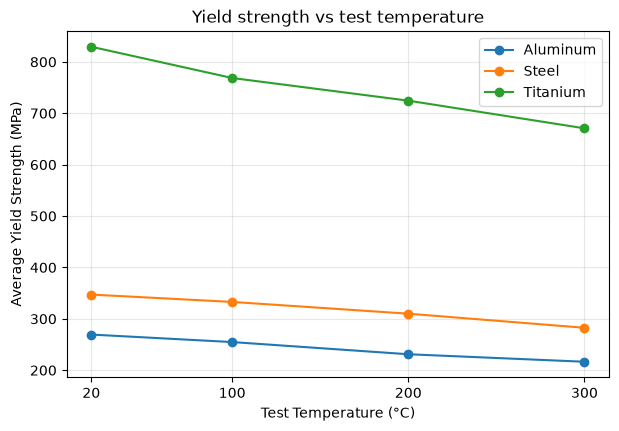

In [75]:
plt.figure(figsize=(7, 4.5))

for material in temp_table.index:
    plt.plot(temp_table.columns, temp_table.loc[material], marker='o', label=material)
plt.xlabel("Test Temperature (°C)")
plt.ylabel("Average Yield Strength (MPa)")
plt.title("Yield strength vs test temperature")
plt.xticks([20,100,200,300])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [76]:
loss_pct = (temp_table[300] - temp_table[20]) / temp_table[20] * 100
print(loss_pct.round(1))

material
Aluminum   -19.6
Steel      -18.6
Titanium   -19.1
dtype: float64



Temperature effect findings

As test temperature rises from 20 °C to 300 °C, the yield strength of all three materials falls steadily, by about 19% for each (aluminum -19.6%, steel -18.6%, titanium -19.1%). Titanium loses the most MPa because it starts highest, but relative to its own strength no material is affected more than the others.

In [78]:
batch_table = df_clean.groupby(['material','batch'])['yield_MPa'].mean().unstack().round(1)
print(batch_table)

batch         A      B      C
material                     
Aluminum  249.6  226.8  257.6
Steel     320.1  306.7  332.0
Titanium  733.3  728.4  783.7


In [80]:
diff_pct = batch_table.sub(batch_table['A'], axis=0).div(batch_table['A'], axis=0)*100
print(diff_pct.round(1))

print(diff_pct.mean().round(1))

batch       A    B    C
material               
Aluminum  0.0 -9.1  3.2
Steel     0.0 -4.2  3.7
Titanium  0.0 -0.7  6.9
batch
A    0.0
B   -4.7
C    4.6
dtype: float64


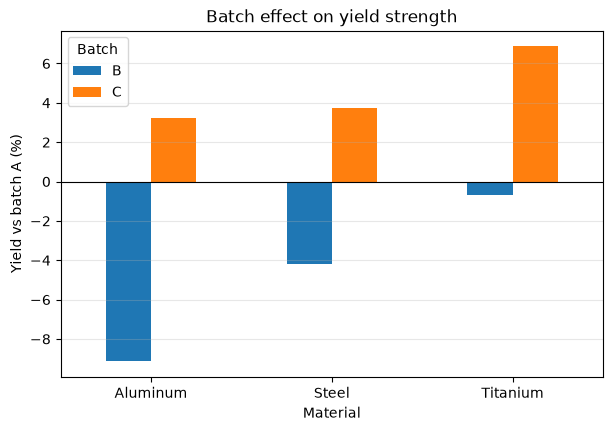

In [84]:
diff_pct.drop(columns='A').plot(kind='bar', figsize=(7,4.5))
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel("Material")
plt.ylabel("Yield vs batch A (%)")
plt.title("Batch effect on yield strength")
plt.xticks(rotation=0)
plt.legend(title="Batch")
plt.grid(axis='y', alpha=0.3)
plt.show()

# 6. Thickness
Does thickness affect elongation? Use a scatter plot and a correlation number. Is the relationship strong, weak or none?

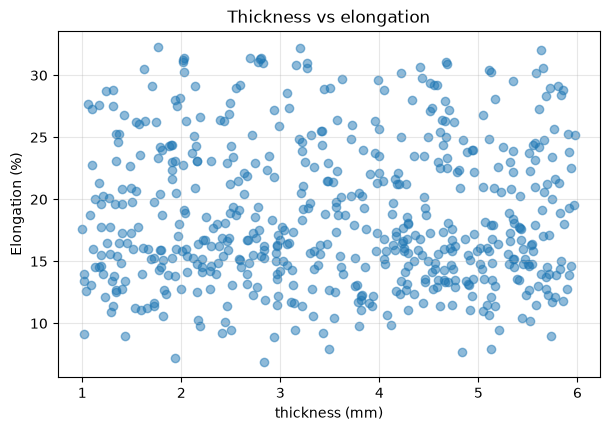

In [87]:
plt.figure(figsize=(7,4.5))
plt.scatter(df_clean['thickness_mm'], df_clean['elongation_pct'], alpha=0.5)
plt.xlabel('thickness (mm)')
plt.ylabel('Elongation (%)')
plt.title("Thickness vs elongation")
plt.grid(alpha=0.3)
plt.show()

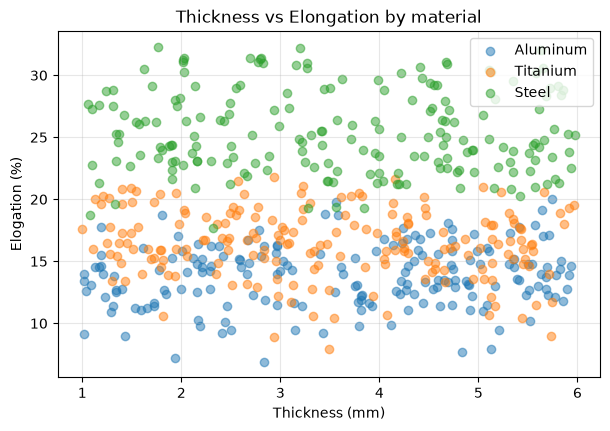

In [93]:
plt.figure(figsize=(7,4.5))

for material in df_clean['material'].unique():
    subset = df_clean[df_clean['material'] == material]
    plt.scatter(subset['thickness_mm'], subset['elongation_pct'], alpha=0.5, label=material)

plt.xlabel("Thickness (mm)")
plt.ylabel("Elogation (%)")
plt.title("Thickness vs Elongation by material")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.show()

In [94]:
overall = df_clean["thickness_mm"].corr(df_clean["elongation_pct"])
print(round(overall, 3))

by_material = df_clean.groupby("material").apply(
    lambda g: g["thickness_mm"].corr(g["elongation_pct"])
)
print(by_material.round(3))

-0.014
material
Aluminum    0.136
Steel      -0.046
Titanium   -0.149
dtype: float64


Thickness findings

> Thickness does not affect elongation. The correlation between thickness and elongation is -0.014 for all tests, which is essentially zero. Inside each material it is also very small and inconsistent (aluminum +0.136, steel -0.046, titanium -0.149), so there is no clear trend in either direction. The scatter plot shows the same: the dots form a flat cloud. The large spread in elongation comes mostly from the material (steel stretches the most), not from thickness. The relationship is weak to none.

### 7. Report function
Write `material_report(df, material)` that returns a dict (average yield, average ultimate, pass rate, number of tests) and saves a chart `report_<material>.png`. Loop over all materials and collect the results into one DataFrame.

In [95]:
def material_report(df, material):
    subset = df[df["material"] == material]
    result = {
        "material": material,
        "tests": len(subset),
    }
    return result

print(material_report(df_clean, "Steel"))

{'material': 'Steel', 'tests': 195}
